In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

housing = fetch_california_housing(as_frame=True)
df_house = housing.frame

print(df_house.columns.tolist())
print(df_house.shape)
df_house.head()

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
from sklearn.model_selection import train_test_split

X = df_house.drop('MedHouseVal', axis=1)
y = df_house['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille entraînement :", X_train.shape)
print("Taille test :", X_test.shape)

Taille entraînement : (16512, 8)
Taille test : (4128, 8)


In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

model_house = RandomForestRegressor(n_estimators=100, random_state=42)
model_house.fit(X_train, y_train)

print("Modèle entraîné avec succès")

Modèle entraîné avec succès


In [4]:
y_pred_house = model_house.predict(X_test)

mae_house = mean_absolute_error(y_test, y_pred_house)
r2_house = r2_score(y_test, y_pred_house)

print("Erreur moyenne absolue (MAE) :", round(mae_house, 3))
print("Score R² :", round(r2_house, 3))

Erreur moyenne absolue (MAE) : 0.328
Score R² : 0.805


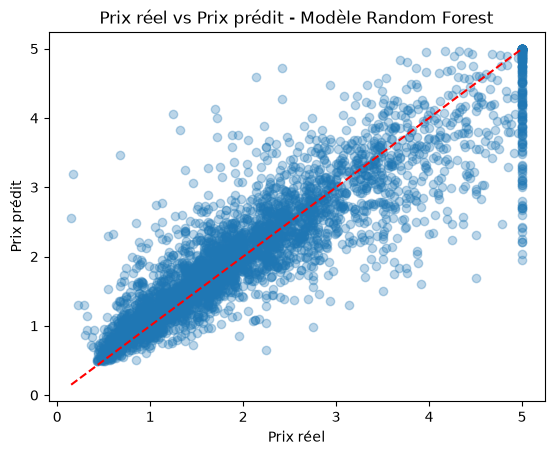

In [5]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_house, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel("Prix réel")
plt.ylabel("Prix prédit")
plt.title("Prix réel vs Prix prédit - Modèle Random Forest")
plt.show()

## Conclusion

L'objectif était de voir si un modèle simple pouvait estimer le prix d'une maison à partir de quelques informations sur son quartier (revenu, âge des logements, population, localisation).

J'ai d'abord testé un dataset de stock pharmaceutique, mais les données n'avaient aucun lien statistique réel entre elles (R2 négatif) - plutôt que de forcer un résultat, j'ai changé pour un dataset réel : le recensement californien de 1990.

Avec ces données, le modèle (Random Forest) explique environ 80% des variations de prix, avec une erreur moyenne d'environ 33 000 dollars. En regardant le graphique final, j'ai aussi remarqué un détail intéressant : les prix avaient été plafonnés à 500 000 dollars au moment du recensement, ce qui explique les écarts sur les maisons les plus chères.

Ce que je retiens : un bon modèle ne sert à rien si les données ne contiennent pas de vrai signal, vérifier leur qualité est une étape aussi importante que la modélisation elle-même.

Pistes d'amélioration : tester d'autres modèles (XGBoost, Gradient Boosting) ou ajouter des variables supplémentaires comme la proximité des écoles ou des commerces

In [1]:
import os
print(os.getcwd())


C:\Users\Dell
